# Analyzing SKIRT outputs

After the simulation has finished running, observables such as band flux and luminosity can be readily extracted from the output files. 

In [1]:

import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import SKIRT_tools
import SKIRT_tools.skirt_tools as sktools

rundir = "/nfspool-0/home/jennydw/SKIRT-tools/tutorials/example" # ABSOLUTE PATH to run directory where output files are stored
name = "m12f_mass56000_cr_700"

# The instrument specifies the projection. The default projections are xy, yz, and xz.
instrument_name = "xy"

# Returns dictionary of fluxes in different bands
flux_dict = sktools.get_band_flux(name, rundir, instrument_name, bands=["SDSS_r"])
# Returns dictioanry of luminosity in different bands
lum_dict = sktools.get_luminosity(name, rundir, bands=['SDSS_r'])
print("Flux in r-band with dust:", flux_dict["SDSS_r"]["total"])
print("Flux in r-band w/o dust:", flux_dict["SDSS_r"]["transparent"])
print("Luminosity in r-band (Lsun):", lum_dict["SDSS_r"])


Flux in r-band with dust: 0.04869799487990632 Jy
Flux in r-band w/o dust: 0.1586021819830529 Jy
Luminosity in r-band (Lsun): 10021530340.0


The bands supported by `SKIRT` and their central wavelengths are:

| Band | Wavelength (micron)|
| :--- | ---: |
| GALEX_FUV | 0.1535079263 |
| GALEX_NUV | 0.2300784642 |
| SDSS_u | 0.3556457276 |
| SDSS_g | 0.4702444002 |
| SDSS_r | 0.6175540451 |
| SDSS_i | 0.748994523 |
| SDSS_z | 0.8946683031 |
| 2MASS_J | 1.239286141 |
| 2MASS_H | 1.649435452 |
| 2MASS_Ks | 2.163824108 |
| WISE_W1 | 3.389693501 |
| WISE_W2 | 4.640627423 |
| WISE_W3 | 12.56759007 |
| WISE_W4 | 22.31422389 |
| HERSCHEL_PACS70 | 70.76977781 |
| HERSCHEL_PACS100 | 100.80266 |
| HERSCHEL_PACS160 | 161.892196 |
| HERSCHEL_SPIRE250 | 252.5495116 |
| HERSCHEL_SPIRE350 | 354.2725745 |
| HERSCHEL_SPIRE500 | 515.3633266 |

# Extracting Band Images

Band images can be extracted with the following code:

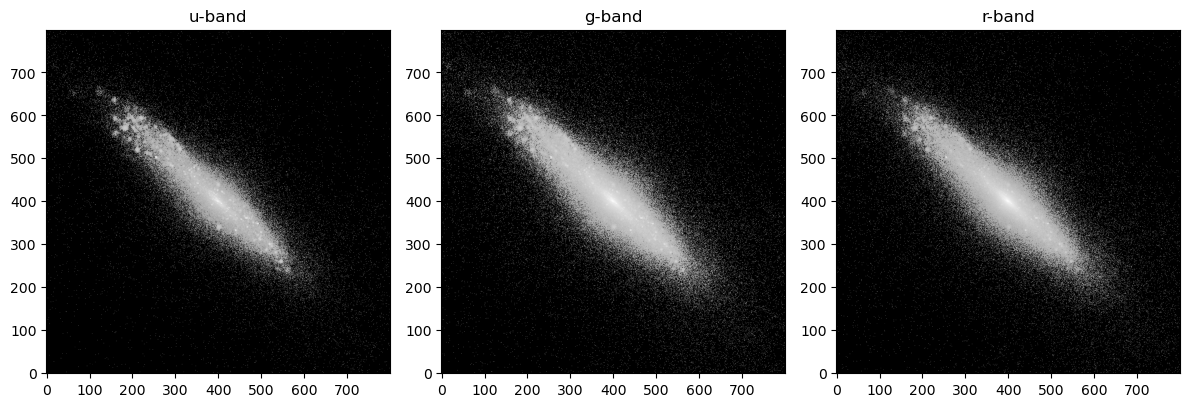

In [2]:

import matplotlib.colors as mcolors

img_dict, header = sktools.get_band_image(name, rundir, instrument_name="xy", bands=['SDSS_u','SDSS_g','SDSS_r'], include_dust=False)

fig, axs = plt.subplots(1,3,figsize=(12,4))
cmap = plt.get_cmap('gray').copy()
cmap.set_bad('black')
axs[0].imshow(img_dict["SDSS_u"], origin="lower", norm=mcolors.LogNorm(), cmap=cmap)
axs[0].set_title("u-band")
axs[1].imshow(img_dict["SDSS_g"], origin="lower", norm=mcolors.LogNorm(), cmap=cmap)
axs[1].set_title("g-band")
axs[2].imshow(img_dict["SDSS_r"], origin="lower", norm=mcolors.LogNorm(), cmap=cmap)
axs[2].set_title("r-band")

plt.tight_layout()
plt.show()


# Creating Mock Images

Creating a mock image is pretty simple. The weights are arbitrary, you can adjust according to what produces the prettiest pictures. 

However, for actual data analysis, you should use the individual band images.

maxden ==  1.9161826 dynrange ==  100 minden ==  0.019161826


/nfspool-0/home/jennydw/FIRE_studio/FIRE_studio/src/firestudio/utils/stellar_utils/make_threeband_image.py:71: RuntimeWarning: divide by zero encountered in log
  r = np.log(r/minnorm) / np.log(maxnorm/minnorm)
/nfspool-0/home/jennydw/FIRE_studio/FIRE_studio/src/firestudio/utils/stellar_utils/make_threeband_image.py:72: RuntimeWarning: divide by zero encountered in log
  g = np.log(g/minnorm) / np.log(maxnorm/minnorm)
/nfspool-0/home/jennydw/FIRE_studio/FIRE_studio/src/firestudio/utils/stellar_utils/make_threeband_image.py:73: RuntimeWarning: divide by zero encountered in log
  b = np.log(b/minnorm) / np.log(maxnorm/minnorm)


maxden ==  1.484081 dynrange ==  100 minden ==  0.014840811
maxden ==  1.4643657 dynrange ==  100 minden ==  0.014643657


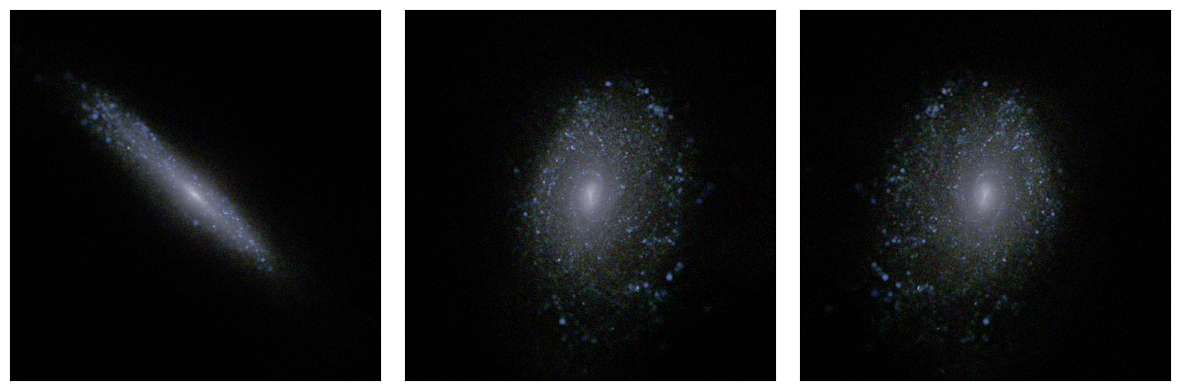

In [3]:

image_xy = sktools.get_mock_image(name, rundir, instrument_name="xy", weights=[1,2,16])
image_yz = sktools.get_mock_image(name, rundir, instrument_name="yz", weights=[1,2,16])
image_xz = sktools.get_mock_image(name, rundir, instrument_name="xz", weights=[1,2,16])

fig, axs = plt.subplots(1,3,figsize=(12,4))
axs[0].imshow(image_xy, origin="lower")
axs[0].set_xticks([])
axs[0].set_yticks([])
axs[1].imshow(image_yz, origin="lower")
axs[1].set_xticks([])
axs[1].set_yticks([])
axs[2].imshow(image_xz, origin="lower")
axs[2].set_xticks([])
axs[2].set_yticks([])
plt.tight_layout()
plt.show()